In [56]:
%load_ext autoreload
%autoreload 2

In [57]:
from project.example_addition import addition

print(addition(5, 5))

10


In [58]:
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler

from kedro.io import DataCatalog
from kedro.config import OmegaConfigLoader
from omegaconf.resolvers import oc # TODO: В ИНТСРУКЦИЮ 

conf_loader = OmegaConfigLoader(
    conf_source="../conf/base",
    custom_resolvers={"oc.env": oc.env}
    )
catalog_config = conf_loader.get("catalog")

catalog = DataCatalog.from_config(catalog_config)

df = catalog.load("boston@raw")

In [59]:
from project.modeling.train import train_model
from project.modeling.split_data import split_data

X_train, X_test, y_train, y_test = split_data(df, target_col="MEDV", scaler=StandardScaler())
train_data = X_train.copy()
train_data["MEDV"] = y_train

test_data = X_test.copy()
test_data["MEDV"] = y_test
model = train_model(train_data, target_col="MEDV")

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

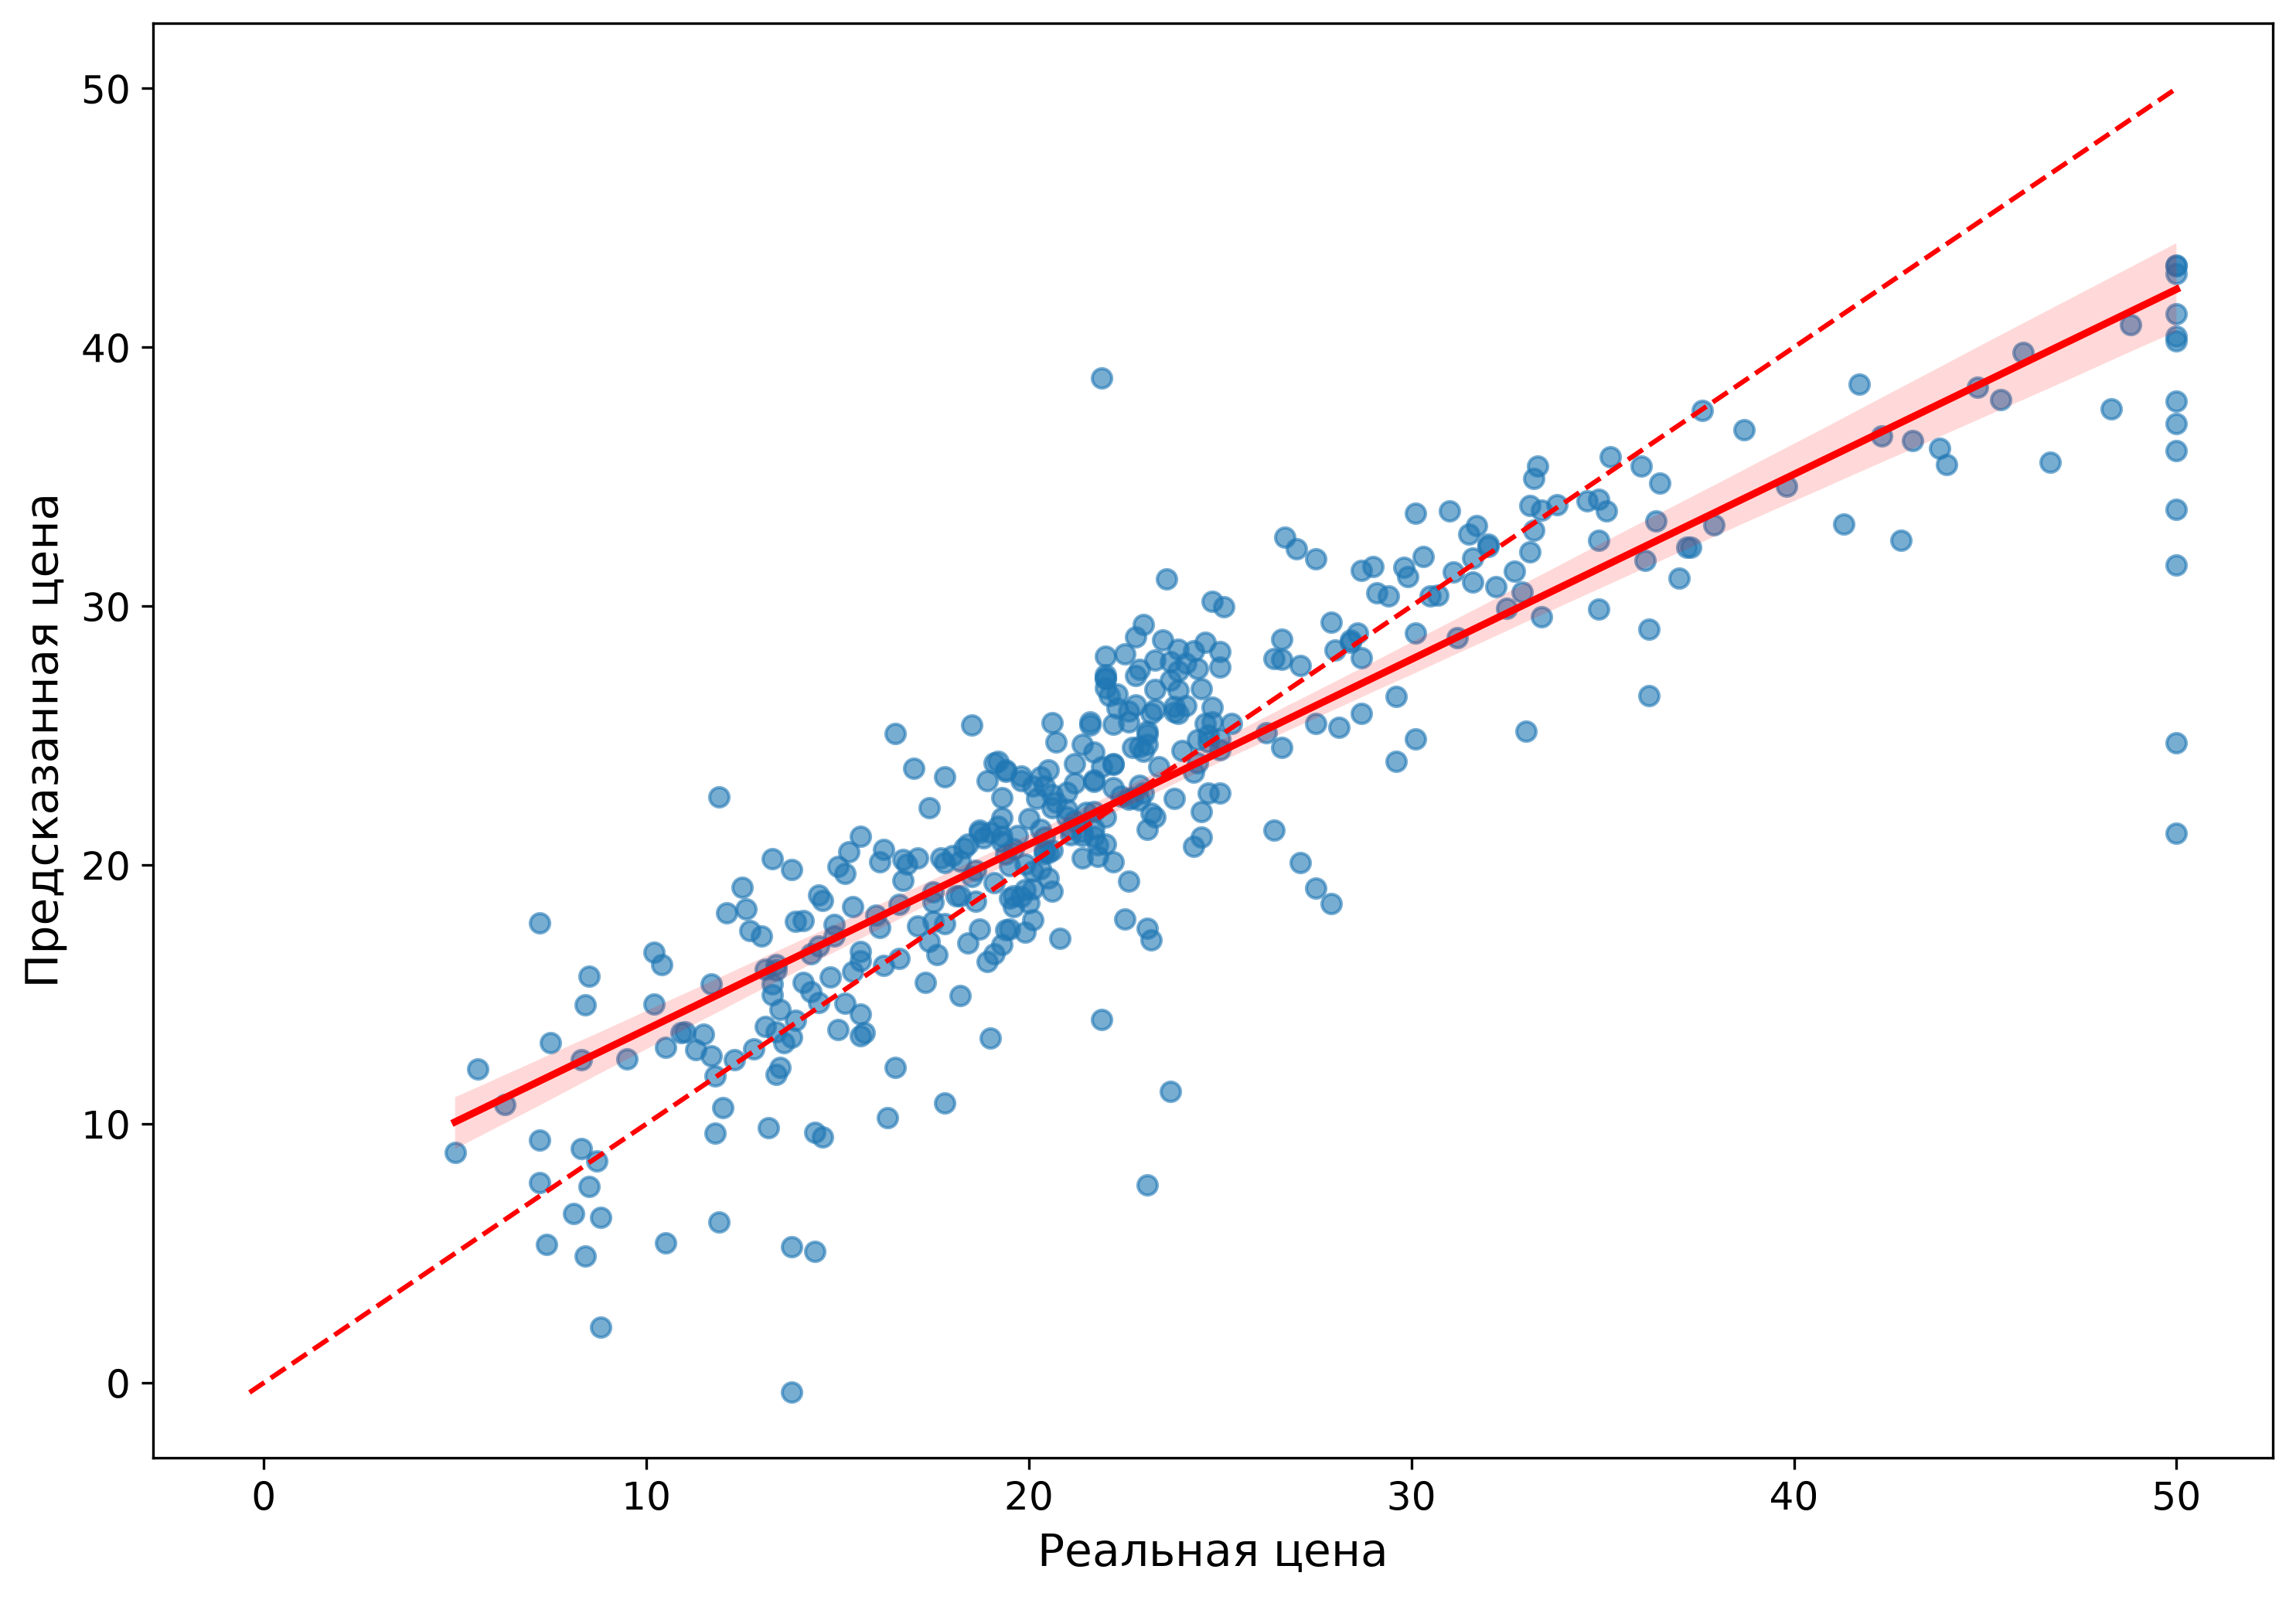

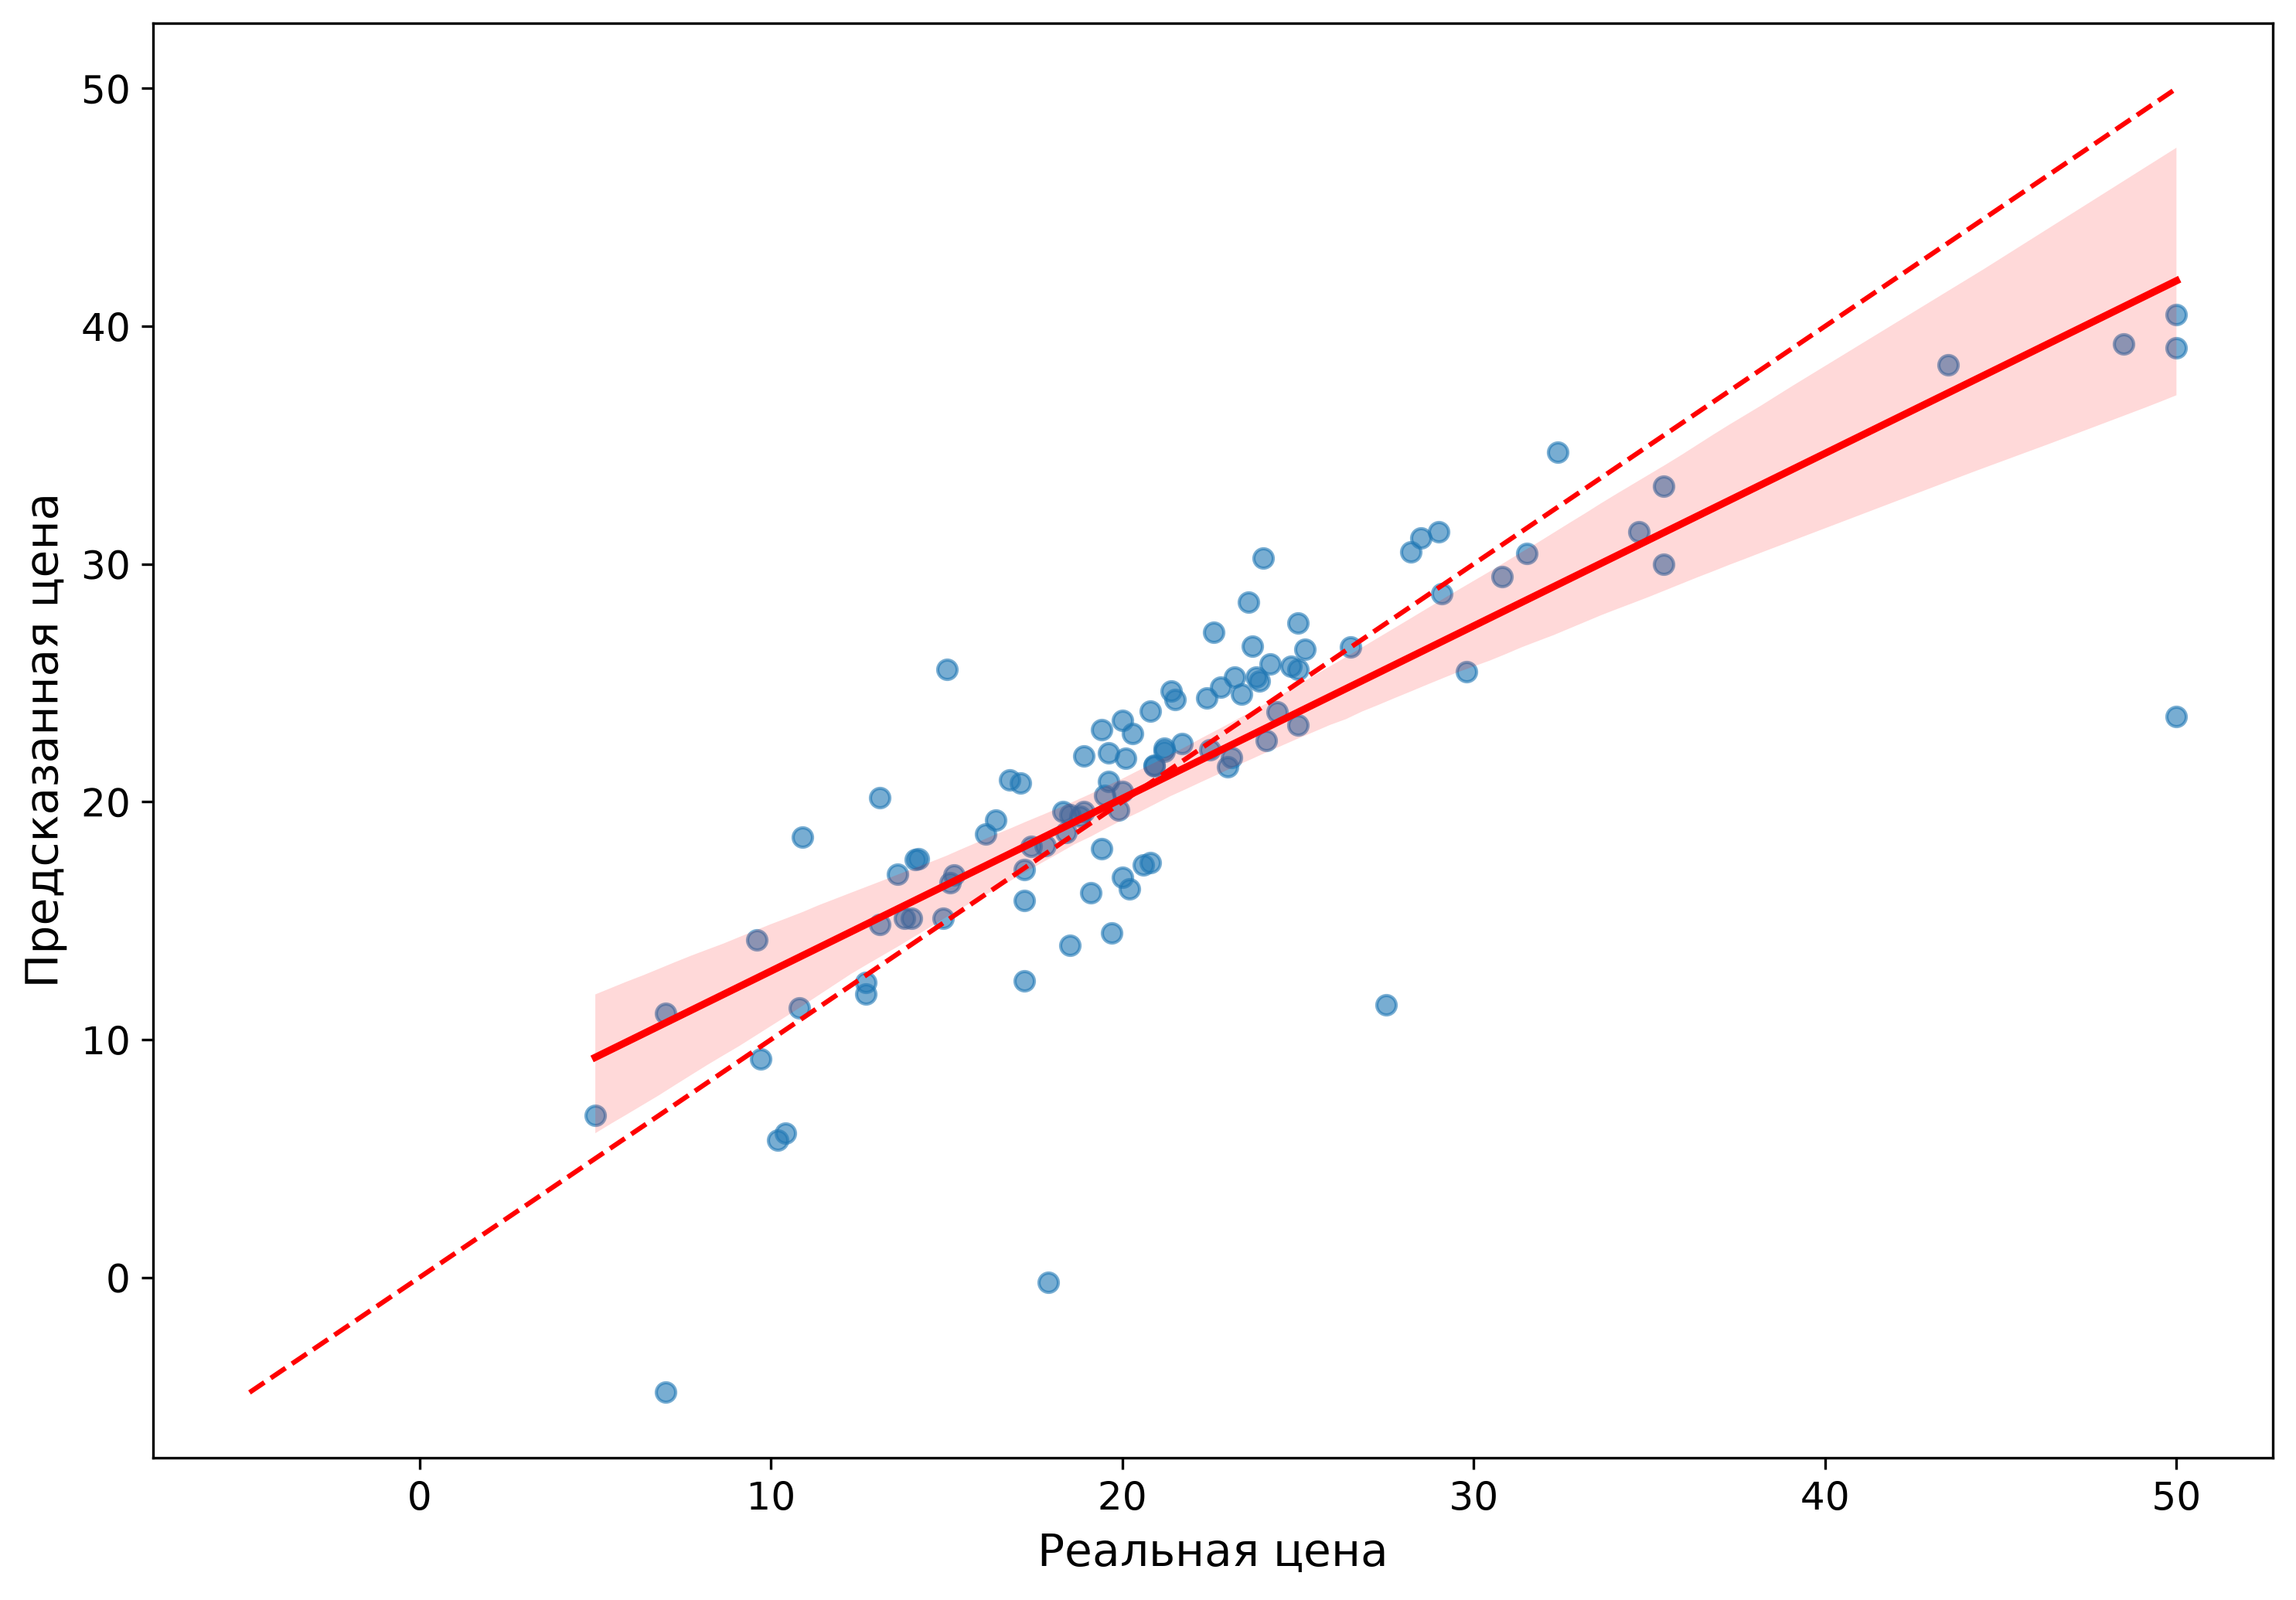

In [ ]:
def scatterplot_sns(y1, y2): 

    plt.figure(figsize=(10, 7), dpi=300)


    sns.regplot(
        x=y1,
        y=y2,
        line_kws={'color': 'red'},
        scatter_kws={"alpha": 0.6}
    )
    
    minimum = min(y1.min(), y2.min())
    maximum = max(y1.max(), y2.max())
    plt.plot([minimum, maximum], [minimum, maximum], 'k--') 
    plt.xlabel('Реальная цена', fontsize = 14)
    plt.ylabel('Предсказанная цена', fontsize=14)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.tight_layout()
    plt.show()


scatterplot_sns(y_train, y_train_pred)
scatterplot_sns(y_test, y_test_pred)

In [61]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

print(f"MAE:  {mean_absolute_error(y_test, y_test_pred):.3f}")
print(f"RMSE: {mean_squared_error(y_test, y_test_pred) ** 0.5:.3f}")
print(f"R²:   {r2_score(y_test, y_test_pred):.3f}")

MAE:  3.192
RMSE: 5.020
R²:   0.656
